# 16b · Why is Summer projects so bad? A leave-one-prompt-out diagnosis

**Question.** Notebook 15 showed that topic, not the threshold, is the biggest source of false flags: on the two held-out prompts the detector flags 0.45% (Electoral college) and 5.2% (Summer projects) of human essays at the strict threshold. Is Summer projects a special case, or is a spread like that normal whenever the model meets a topic it never saw?

**Experiment** (run overnight by `scripts/lopo_run.sh`; this notebook only reads the saved scores). For each of the **13 ordinary prompts**, fine-tune DistilRoBERTa with the exact recipe of notebook 08 on the train essays of the *other 12 prompts*, choose the 1%-false-flag threshold on the val humans of those 12 prompts, then count how many human essays of the **left-out prompt** (train + val + test essays of that prompt: the model never saw this topic) get flagged. That gives 13 held-out-topic false-flag rates. Then one fold (the one closest to the median) was rerun with two more seeds to separate seed noise from topic.

**Rules kept.** Summer projects and Electoral college are *not* used to choose anything here: they were not in any training set, threshold or selection. They are only placed on the picture afterwards, using the original model of notebook 08 (trained on all 13 prompts, so for it these two prompts are unseen in exactly the same way). Nothing was tuned on any of these results.

1. The spread of the 13 rates, with Wilson intervals; is it more than sampling noise?
2. Where Summer projects and Electoral college fall in it.
3. Seed noise versus topic.
4. What the worst prompts have in common (essay length, misspellings, GPT-2 perplexity, AI-vocabulary share) and ten real flagged essays.

In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
import sys
sys.path.append('..')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.data import load_splits
from src.evaluate import wilson_interval, threshold_for_fpr, ClusterSampler, bootstrap_interval

SEED, N_BOOT = 42, 1000
LOPO = '../results/16b_lopo'
SUMMER, ELECTORAL = 'Summer projects', 'Does the electoral college work?'
pd.set_option('display.width', 230); pd.set_option('display.max_colwidth', 90)
HUMAN, AI = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.edgecolor': '#9a9a94', 'axes.titleweight': 'bold'})

data = load_splits()
log = pd.read_csv(f'{LOPO}/log.csv')
print(log.groupby('seed').size().to_string())
print(f"folds: {len(log[log['seed'] == 42])} with seed 42; training minutes per fold: median {log['minutes'].median():.1f}, "
      f"val AUC {log['val_auc'].min():.5f} to {log['val_auc'].max():.5f}")

seed
42    13
43     1
44     1
folds: 13 with seed 42; training minutes per fold: median 15.4, val AUC 0.99967 to 0.99983


## 1 · The 13 left-out-prompt false-flag rates

Each fold file holds the scores of its three groups. The fold's threshold is the score that flags 1% of the **val humans of the other 12 prompts** (and, for comparison with notebook 15, 0.5%). Every human essay of the left-out prompt is then flagged or not.

In [2]:
def load_fold(fold, seed=42):
    s = pd.read_csv(f'{LOPO}/scores_fold{fold:02d}_seed{seed}.csv', index_col='row_id')
    prompt = s.loc[s['role'] == 'left_out', 'prompt_name'].iloc[0]
    assert set(s.loc[s['role'] == 'left_out', 'prompt_name']) == {prompt}
    assert prompt not in set(s.loc[s['role'] != 'left_out', 'prompt_name']), 'left-out prompt appears in the other groups'
    assert not {SUMMER, ELECTORAL} & set(s['prompt_name']), 'a held-out prompt leaked into the fold files'
    vh = s[(s['role'] == 'other_val') & (s['label'] == 0)]['logit']
    thr = {t: threshold_for_fpr(vh, t) for t in (0.01, 0.005)}
    left = s[s['role'] == 'left_out'].copy()
    for t in thr: left[f'flag_{t}'] = left['logit'] >= thr[t]
    return prompt, thr, left, s

rows, essays = [], []
for fold in range(13):
    prompt, thr, left, s = load_fold(fold)
    h, a = left[left['label'] == 0], left[left['label'] == 1]
    row = {'fold': fold, 'prompt': prompt, 'humans': len(h), 'AI': len(a), 'val AUC': float(log[(log['fold'] == fold) & (log['seed'] == 42)]['val_auc'].iloc[0])}
    for t in (0.01, 0.005):
        k = int(h[f'flag_{t}'].sum()); lo, hi = wilson_interval(k, len(h))
        row.update({f'k_{t}': k, f'rate_{t}': 100 * k / len(h), f'lo_{t}': 100 * lo, f'hi_{t}': 100 * hi, f'thr_{t}': thr[t],
                    f'AI caught_{t}': 100 * float(a[f'flag_{t}'].mean())})
    rows.append(row); essays.append(h.assign(fold=fold))
lopo = pd.DataFrame(rows).set_index('prompt').sort_values('rate_0.01', ascending=False)
essays = pd.concat(essays)
t = lopo.copy()
t['1% threshold: humans flagged'] = [f"{r['rate_0.01']:.2f}% [{r['lo_0.01']:.2f}, {r['hi_0.01']:.2f}] ({r['k_0.01']}/{r['humans']})" for _, r in t.iterrows()]
t['0.5% threshold: humans flagged'] = [f"{r['rate_0.005']:.2f}% [{r['lo_0.005']:.2f}, {r['hi_0.005']:.2f}] ({r['k_0.005']}/{r['humans']})" for _, r in t.iterrows()]
t[['1% threshold: humans flagged', '0.5% threshold: humans flagged', 'AI caught_0.01', 'val AUC']].round(3)

,1% threshold: humans flagged,0.5% threshold: humans flagged,AI caught_0.01,val AUC
prompt,,,,
Seeking multiple opinions,"5.80% [4.74, 7.07] (90.0/1552.0)","3.93% [3.07, 5.02] (61/1552)",99.530,1.0
Distance learning,"5.52% [4.63, 6.56] (119.0/2157.0)","2.97% [2.33, 3.77] (64/2157)",99.705,1.0
Community service,"5.19% [4.19, 6.41] (80.0/1542.0)","2.59% [1.91, 3.51] (40/1542)",99.751,1.0
Exploring Venus,"4.73% [3.85, 5.79] (88.0/1862.0)","2.69% [2.04, 3.52] (50/1862)",100.000,1.0
"""A Cowboy Who Rode the Waves""","4.30% [3.35, 5.51] (59.0/1372.0)","1.53% [1.00, 2.33] (21/1372)",99.407,1.0
Mandatory extracurricular activities,"3.47% [2.70, 4.46] (58.0/1670.0)","1.98% [1.41, 2.76] (33/1670)",99.673,1.0
Facial action coding system,"2.54% [1.96, 3.29] (55.0/2167.0)","0.97% [0.63, 1.48] (21/2167)",99.701,1.0
Grades for extracurricular activities,"1.60% [1.09, 2.33] (26.0/1626.0)","0.80% [0.47, 1.36] (13/1626)",99.308,1.0
Phones and driving,"1.54% [0.98, 2.42] (18.0/1168.0)","0.94% [0.53, 1.68] (11/1168)",100.000,1.0


### Is the spread more than sampling noise?

Three views:

- **Pooled rate and observed range.** If every prompt had the same true false-flag rate, how far apart could the best and worst of 13 prompts of these sizes land by chance alone? We simulate that (10,000 draws from a binomial with the pooled rate and each prompt's own size) and compare with the observed max − min.
- **Chi-square test of homogeneity** across the 13 prompts.
- **Between-prompt spread on the logit scale** (DerSimonian–Laird random-effects estimate τ): the standard deviation of the true prompt-level log-odds of a false flag after removing the sampling noise of each rate.

In [3]:
def spread_stats(k, n):
    k, n = np.asarray(k), np.asarray(n)
    pooled = k.sum() / n.sum()
    rng = np.random.default_rng(SEED)
    sim = rng.binomial(n, pooled, size=(10_000, len(n))) / n
    sim_range = 100 * (sim.max(axis=1) - sim.min(axis=1))
    obs_range = 100 * (k / n).max() - 100 * (k / n).min()
    chi2, p, *_ = stats.chi2_contingency(np.c_[k, n - k])
    # DerSimonian-Laird on logit(rate), 0.5 continuity correction so a rate of 0 stays finite
    y = np.log((k + 0.5) / (n - k + 0.5)); v = 1 / (k + 0.5) + 1 / (n - k + 0.5); w = 1 / v
    q = float((w * (y - (w * y).sum() / w.sum()) ** 2).sum())
    tau2 = max(0.0, (q - (len(k) - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    return dict(pooled=100 * pooled, lo=100 * wilson_interval(int(k.sum()), int(n.sum()))[0], hi=100 * wilson_interval(int(k.sum()), int(n.sum()))[1],
                obs_range=obs_range, sim_range_median=np.median(sim_range), sim_range_95=np.percentile(sim_range, 95), p_range=(sim_range >= obs_range).mean(),
                chi2=chi2, chi2_p=p, tau=np.sqrt(tau2), median=100 * np.median(k / n), q1=100 * np.percentile(k / n, 25), q3=100 * np.percentile(k / n, 75),
                min=100 * (k / n).min(), max=100 * (k / n).max())

sp = {t: spread_stats(lopo[f'k_{t}'], lopo['humans']) for t in (0.01, 0.005)}
pd.DataFrame(sp).T.rename(index={0.01: '1% threshold', 0.005: '0.5% threshold'}).round(3).T

,1% threshold,0.5% threshold
pooled,2.864,1.476
lo,2.656,1.327
hi,3.088,1.640
obs_range,5.437,3.749
sim_range_median,1.330,0.968
sim_range_95,1.937,1.394
p_range,0.000,0.000
chi2,308.082,217.149
chi2_p,0.000,0.000
tau,0.634,0.706


## 2 · Where Summer projects and Electoral college fall

For the two held-out prompts the false-flag rate comes from the **original** model (notebook 08, trained on all 13 prompts) with its val-chosen thresholds from `results/09_thresholds.csv` (1% = logit 4.67, 0.5% = logit 7.80), counted on *all* human essays of the prompt, exactly as above. They are drawn on the same axis as the 13 left-out prompts.

In [4]:
base = pd.read_csv('../results/15_scores.csv', index_col='row_id')
ho = data.loc[base.index]
ho = ho[(ho['split'] == 'heldout_prompt') & (ho['label'] == 0)].assign(logit=base['roberta'])
THR_ORIG = {0.01: 4.666, 0.005: 7.796}
held = {}
for name, p in [('Summer projects', SUMMER), ('Electoral college', ELECTORAL)]:
    d = ho[ho['prompt_name'] == p]
    held[name] = {}
    for t, thr in THR_ORIG.items():
        k = int((d['logit'] >= thr).sum()); lo, hi = wilson_interval(k, len(d))
        held[name][t] = dict(k=k, n=len(d), rate=100 * k / len(d), lo=100 * lo, hi=100 * hi)
rank_rows = []
for name in held:
    for t in (0.01, 0.005):
        r = held[name][t]
        below = int((lopo[f'rate_{t}'] < r['rate']).sum())
        rank_rows.append({'prompt': name, 'threshold': f'{t:.1%}', 'rate': f"{r['rate']:.2f}% [{r['lo']:.2f}, {r['hi']:.2f}] ({r['k']}/{r['n']})",
                          'LOPO rates below it (of 13)': below, 'LOPO min / median / max %': f"{lopo[f'rate_{t}'].min():.2f} / {lopo[f'rate_{t}'].median():.2f} / {lopo[f'rate_{t}'].max():.2f}",
                          'above the highest LOPO interval end?': bool(r['lo'] > lopo[f'hi_{t}'].max()), 'below the lowest LOPO interval start?': bool(r['hi'] < lopo[f'lo_{t}'].min())})
print('(original model, all human essays of each held-out prompt; rate and position among the 13 left-out-prompt rates)')
pd.DataFrame(rank_rows).set_index(['prompt', 'threshold'])

(original model, all human essays of each held-out prompt; rate and position among the 13 left-out-prompt rates)


rate  LOPO rates below it (of 13) LOPO min / median / max %  above the highest LOPO interval end?  below the lowest LOPO interval start?
prompt            threshold                                                                                                                                                                   
Summer projects   1.0%       7.71% [6.55, 9.06] (135/1750)                           13        0.36 / 2.54 / 5.80                                 False                                  False
                  0.5%        5.14% [4.20, 6.28] (90/1750)                           13        0.18 / 0.97 / 3.93                                 False                                  False
Electoral college 1.0%        1.29% [0.93, 1.79] (35/2714)                            3        0.36 / 2.54 / 5.80                                 False                                  False
                  0.5%        0.44% [0.25, 0.77] (12/2714)                            3        0.18 / 0.97 / 3.93                                 False                                  False

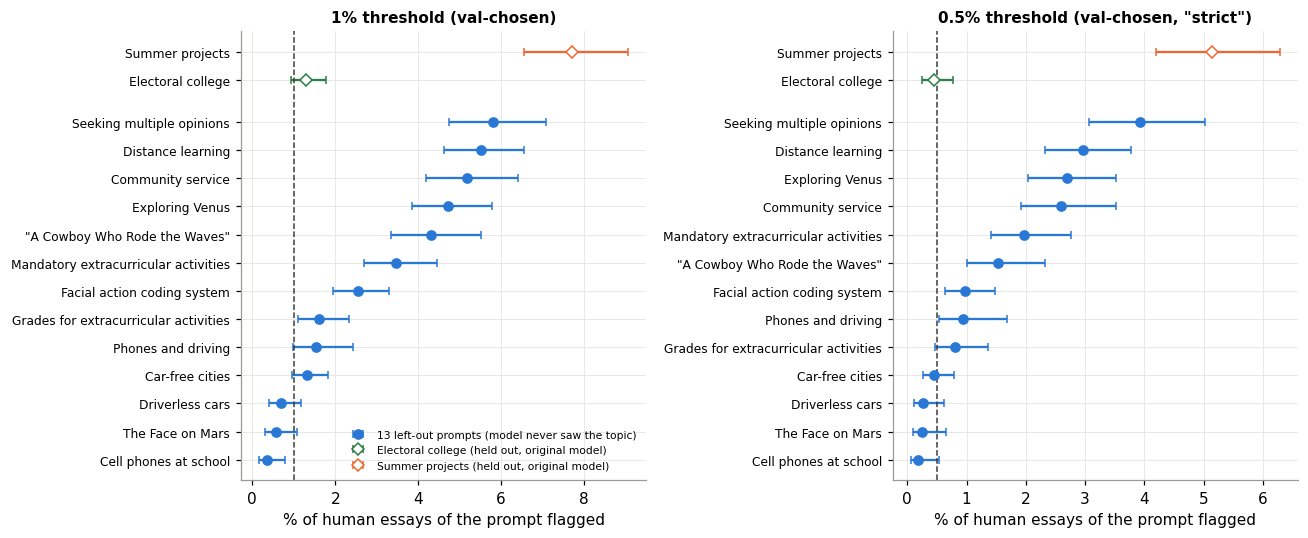

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)
for ax, t, title in zip(axes, (0.01, 0.005), ('1% threshold (val-chosen)', '0.5% threshold (val-chosen, "strict")')):
    d = lopo.sort_values(f'rate_{t}')
    y = np.arange(len(d))
    ax.errorbar(d[f'rate_{t}'], y, xerr=[d[f'rate_{t}'] - d[f'lo_{t}'], d[f'hi_{t}'] - d[f'rate_{t}']], fmt='o', color=HUMAN, ecolor=HUMAN, capsize=2.5, label='13 left-out prompts (model never saw the topic)')
    labels = list(d.index)
    for name, c in [('Electoral college', '#2d7d46'), ('Summer projects', AI)]:
        r = held[name][t]; yy = len(d) + (1 if name == 'Electoral college' else 2) - 0.5
        ax.errorbar([r['rate']], [yy], xerr=[[r['rate'] - r['lo']], [r['hi'] - r['rate']]], fmt='D', mfc='white', color=c, ecolor=c, capsize=2.5, label=f'{name} (held out, original model)')
        labels.append(name)
    ax.set_yticks(list(y) + [len(d) + 0.5, len(d) + 1.5]); ax.set_yticklabels(labels, fontsize=8)
    ax.axvline(100 * t, color='#3d3d3a', linestyle='--', linewidth=1)
    ax.set_xlabel('% of human essays of the prompt flagged'); ax.set_title(title, fontsize=10)
axes[0].legend(loc='lower right', fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig('../images/16b_lopo_spread.png', dpi=150, bbox_inches='tight'); plt.show()

## 3 · Seed noise versus topic

The fold whose left-out rate was closest to the median of the 13 was rerun with two more seeds (43 and 44; the seed changes the classifier head's initial weights and the order of the training batches, nothing else). If the prompt-to-prompt spread were mostly seed noise, three seeds on one prompt would spread as widely as 13 prompts do. Each seed gets its own threshold from its own other-prompt val humans.

In [6]:
seed_fold = int(log[log['seed'] != 42]['fold'].iloc[0])
seeds = sorted(log[log['fold'] == seed_fold]['seed'].unique())
print('seed-noise fold:', seed_fold, '| seeds:', seeds)
runs = {}
for sd in seeds:
    prompt, thr, left, s = load_fold(seed_fold, sd)
    runs[sd] = left[left['label'] == 0]
rows = []
for sd, h in runs.items():
    k = int(h['flag_0.01'].sum()); lo, hi = wilson_interval(k, len(h))
    rows.append({'seed': sd, 'threshold (logit)': float(log[(log['fold'] == seed_fold) & (log['seed'] == sd)]['threshold_1pct'].iloc[0]), 'humans flagged': f'{k}/{len(h)}',
                 'rate %': 100 * k / len(h), 'Wilson 95% [lo, hi]': f'[{100 * lo:.2f}, {100 * hi:.2f}]'})
seed_tab = pd.DataFrame(rows).set_index('seed'); print(prompt); print(seed_tab.round(3).to_string())

flags = pd.DataFrame({sd: h['flag_0.01'] for sd, h in runs.items()})
logits = pd.DataFrame({sd: h['logit'] for sd, h in runs.items()})
n_flag = flags.sum(axis=1)
print(f"\nessays flagged by all {len(seeds)} seeds: {(n_flag == len(seeds)).sum()} | by some but not all: {((n_flag > 0) & (n_flag < len(seeds))).sum()} | by at least one: {(n_flag > 0).sum()}")
print('Spearman correlation of the essays\' logits between seeds:', {f'{a}-{b}': round(stats.spearmanr(logits[a], logits[b])[0], 3) for i, a in enumerate(seeds) for b in seeds[i + 1:]})

rates = seed_tab['rate %'].to_numpy()
prompt_sd = 100 * np.std(lopo['rate_0.01'] / 100, ddof=1)
print(f"\nSD of the false-flag rate across the {len(seeds)} seeds (one prompt): {np.std(rates, ddof=1):.2f} points; range {rates.min():.2f} to {rates.max():.2f}")
print(f"SD of the false-flag rate across the 13 prompts (one seed):    {prompt_sd:.2f} points; range {lopo['rate_0.01'].min():.2f} to {lopo['rate_0.01'].max():.2f}")
print(f"seed variance / prompt variance = {np.var(rates, ddof=1) / np.var(lopo['rate_0.01'], ddof=1):.3f}  (a rough share of the prompt-to-prompt variance that seed noise could explain; from ONE prompt and three seeds, so itself very uncertain)")

seed-noise fold: 7 | seeds: [np.int64(42), np.int64(43), np.int64(44)]
Facial action coding system
      threshold (logit) humans flagged  rate % Wilson 95% [lo, hi]
seed                                                              
42                3.660        55/2167   2.538        [1.96, 3.29]
43                3.957        41/2167   1.892        [1.40, 2.56]
44                4.495        52/2167   2.400        [1.83, 3.13]

essays flagged by all 3 seeds: 28 | by some but not all: 44 | by at least one: 72
Spearman correlation of the essays' logits between seeds: {'42-43': np.float64(0.895), '42-44': np.float64(0.899), '43-44': np.float64(0.884)}

SD of the false-flag rate across the 3 seeds (one prompt): 0.34 points; range 1.89 to 2.54
SD of the false-flag rate across the 13 prompts (one seed):    2.02 points; range 0.36 to 5.80
seed variance / prompt variance = 0.028  (a rough share of the prompt-to-prompt variance that seed noise could explain; from ONE prompt and three seeds, 

## 4 · What do the worst prompts have in common?

Per human essay, for the 13 ordinary prompts: **length** (words), **misspelling rate** (share of tokens missing from the GloVe vocabulary, the same measure as notebook 14), **GPT-2 log-perplexity** (saved in notebook 10), and **AI-vocabulary share** (share of the essay's tokens that belong to the 300 words most over-represented in AI essays, learned on *on-topic* train essays only, so topic words do not count: style words such as "furthermore" or "essay" do). Per prompt we also have the share of AI essays in the data, the share of human essays that come from the original Kaggle file versus Persuade, and the fraction of AI essays that are off-topic. Grade level is not in this dataset (Phase 6).

Caution: 13 prompts is a small sample for a prompt-level correlation; treat those as hints. The stronger test is **within a prompt**: after standardising each feature inside its prompt, do the flagged humans differ from the other humans of the same prompt?

In [7]:
import gensim.downloader as gensim_api
from gensim.utils import simple_preprocess
from sklearn.feature_extraction.text import CountVectorizer

glove_vocab = set(gensim_api.load('glove-wiki-gigaword-100').key_to_index)
gpt2 = pd.read_csv('../results/10_gpt2_features.csv', index_col='row_id')
ordinary = data[data['split'].isin(['train', 'val', 'test'])]
hum = ordinary[ordinary['label'] == 0].copy()
tok = lambda t: simple_preprocess(t, min_len=1, max_len=30)
t0 = time.time()
toks = [tok(t) for t in hum['text']]
hum['misspell_pct'] = [100 * np.mean([w not in glove_vocab for w in ts] or [0]) for ts in toks]
hum['log_ppl'] = gpt2.loc[hum.index, 'log_ppl']

# AI-typical vocabulary: log-odds of each word in AI vs human ON-TOPIC TRAIN essays (topic words from off-topic AI essays excluded)
fit = ordinary[(ordinary['split'] == 'train') & ordinary['on_topic']]
cv = CountVectorizer(tokenizer=tok, lowercase=False, token_pattern=None, min_df=20)
X = cv.fit_transform(fit['text'])
a = np.asarray(X[(fit['label'] == 1).to_numpy()].sum(axis=0)).ravel(); h = np.asarray(X[(fit['label'] == 0).to_numpy()].sum(axis=0)).ravel()
logodds = np.log((a + 1) / (a.sum() + len(a))) - np.log((h + 1) / (h.sum() + len(a)))
ai_words = set(np.array(cv.get_feature_names_out())[np.argsort(-logodds)[:300]])
print('example AI-typical words:', ', '.join(np.array(cv.get_feature_names_out())[np.argsort(-logodds)[:25]]))
hum['ai_vocab_pct'] = [100 * np.mean([w in ai_words for w in ts] or [0]) for ts in toks]
print(f'features for {len(hum):,} human essays in {time.time() - t0:.0f}s')

example AI-typical words: grinspoon, bikeable, sprawl, oxides, respiratory, symmetrical, sustainable, initiatives, mitigate, sustainability, livable, nitrogen, walkable, mitigating, policymakers, cycling, livability, centric, vibrant, counterclaims, walkability, proponents, amenities, fostering, marine


features for 22,907 human essays in 42s


In [8]:
FEATURES = ['n_words', 'misspell_pct', 'log_ppl', 'ai_vocab_pct']
pm = hum.groupby('prompt_name')[FEATURES].median().add_suffix(' (median)')
pm['misspell_pct (mean)'] = hum.groupby('prompt_name')['misspell_pct'].mean()
meta = ordinary.groupby('prompt_name').agg(AI_share=('label', 'mean'), essays=('label', 'size'))
meta['AI_share'] *= 100
meta['human essays from Kaggle train_essays %'] = 100 * hum.groupby('prompt_name')['source'].apply(lambda s: (s == 'train_essays').mean())
ai_off = ordinary[ordinary['label'] == 1].groupby('prompt_name')['on_topic'].apply(lambda s: 100 * (1 - s.mean()))
meta['AI essays off-topic %'] = ai_off
prompt_table = lopo[['rate_0.01', 'rate_0.005']].join(pm).join(meta).sort_values('rate_0.01', ascending=False)
print(prompt_table.round(2).to_string())

print('\nSpearman correlation of the prompt-level false-flag rate (1%) with each prompt property (n = 13 prompts; hints only):')
corr = []
for c in [c for c in prompt_table.columns if c not in ('rate_0.01', 'rate_0.005')]:
    r, p = stats.spearmanr(prompt_table['rate_0.01'], prompt_table[c]); corr.append({'property': c, 'Spearman rho': r, 'p': p})
pd.DataFrame(corr).round(3).to_string(index=False)

                                       rate_0.01  rate_0.005  n_words (median)  misspell_pct (median)  log_ppl (median)  ai_vocab_pct (median)  misspell_pct (mean)  AI_share  essays  human essays from Kaggle train_essays %  AI essays off-topic %
prompt                                                                                                                                                                                                                                               
Seeking multiple opinions                   5.80        3.93             484.0                   0.00              2.97                   0.00                 0.43     68.70    4959                                     0.00                  91.25
Distance learning                           5.52        2.97             550.0                   0.00              3.22                   0.22                 0.53     58.61    5211                                     0.00                  60.15
Community servic

'                               property  Spearman rho     p\n                       n_words (median)         0.250 0.409\n                  misspell_pct (median)        -0.176 0.566\n                       log_ppl (median)        -0.275 0.364\n                  ai_vocab_pct (median)        -0.007 0.981\n                    misspell_pct (mean)         0.137 0.655\n                               AI_share         0.560 0.046\n                                 essays         0.385 0.194\nhuman essays from Kaggle train_essays %        -0.231 0.447\n                  AI essays off-topic %         0.527 0.064'

In [9]:
# within a prompt: do flagged humans differ from the other humans of the same prompt? (features standardised inside each prompt)
e = essays.join(hum[FEATURES]).dropna(subset=FEATURES).copy()
e['flag'] = e['flag_0.01'].astype(bool)
for f in FEATURES:
    e[f + '_z'] = e.groupby('prompt_name')[f].transform(lambda x: (x - x.mean()) / x.std())
sampler = ClusterSampler(hum.loc[e.index, 'dup_cluster'])
rows = []
for f in FEATURES:
    z, fl = e[f + '_z'].to_numpy(), e['flag'].to_numpy()
    def stat(r): return float(z[r][fl[r]].mean() - z[r][~fl[r]].mean()) if fl[r].any() else np.nan
    d, lo, hi = bootstrap_interval(stat, len(e), groups=hum.loc[e.index, 'dup_cluster'].to_numpy(), n_boot=N_BOOT)
    rows.append({'feature': f, 'flagged minus other humans (SD units, within prompt)': d, 'lo': lo, 'hi': hi,
                 'flagged median': e.loc[e['flag'], f].median(), 'others median': e.loc[~e['flag'], f].median()})
print(f"{int(e['flag'].sum())} flagged humans vs {int((~e['flag']).sum())} others, pooled over the 13 left-out prompts")
pd.DataFrame(rows).set_index('feature').round(3)

656 flagged humans vs 22251 others, pooled over the 13 left-out prompts


,"flagged minus other humans (SD units, within prompt)",lo,hi,flagged median,others median
feature,,,,,
n_words,-0.112,-0.185,-0.036,351.000,367.000
misspell_pct,-0.428,-0.480,-0.373,0.000,0.556
log_ppl,-0.946,-1.008,-0.884,2.948,3.343
ai_vocab_pct,0.537,0.428,0.654,0.204,0.000


In [10]:
# ten real flagged essays: 3 each from the two worst prompts, 2 each from the next two worst (random, seed 42)
worst = list(lopo.index[:4])
rng = np.random.default_rng(SEED)
picked = []
for p, n in zip(worst, (3, 3, 2, 2)):
    pool = e[(e['prompt_name'] == p) & e['flag']]
    picked += list(pool.sample(n, random_state=SEED).index)
print('worst four prompts (1% threshold):', worst, '\n')
for rid in picked:
    r, text = e.loc[rid], data.loc[rid, 'text']
    print(f"[{r['prompt_name']} | {data.loc[rid, 'source']} | logit {r['logit']:+.1f} | {int(r['n_words'])} words | misspell {r['misspell_pct']:.1f}% | AI-vocab {r['ai_vocab_pct']:.1f}% | log-ppl {r['log_ppl']:.2f}]")
    print('   ', text[:520].replace('\n', ' '), '...\n')

worst four prompts (1% threshold): ['Seeking multiple opinions', 'Distance learning', 'Community service', 'Exploring Venus'] 

[Seeking multiple opinions | persuade_corpus | logit +9.1 | 179 words | misspell 0.0% | AI-vocab 0.0% | log-ppl 2.81]
    When people ask for advice, they talk to more than one person, which helps them make a better choice. The reason to why seeking multiple opinions can help people make a better choice is because they have different opinions and it gives more options to make than just one.  When seeking advice, asking advice from different opinions can help make a better choice. For one, multiple opinions have different backgrounds and answers. Second, multiple opinions have different levels of understanding, ensuring that you get a  ...

[Seeking multiple opinions | persuade_corpus | logit +5.1 | 425 words | misspell 0.0% | AI-vocab 0.0% | log-ppl 3.23]
    Finding a wise person for advice can be challenging, everyone needs advice sometimes, but taking it fr

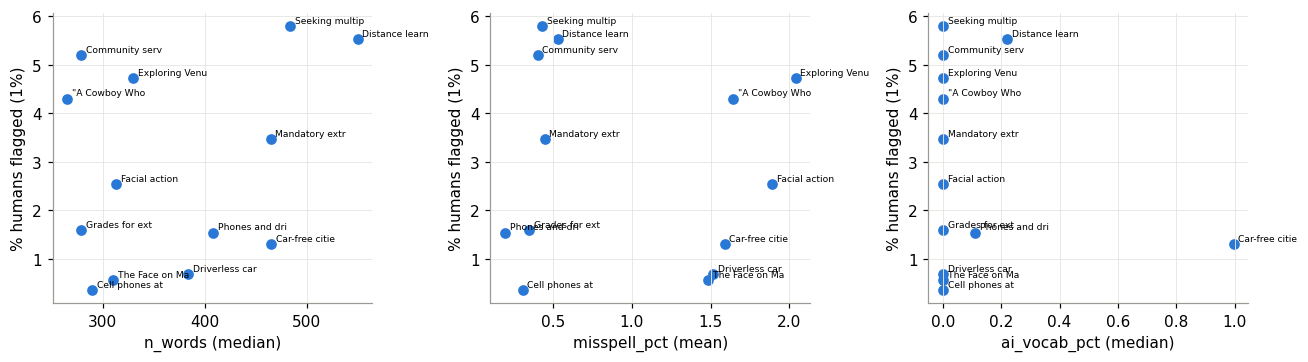

saved


In [11]:
# saved for Phase 4 and later phases
prompt_table.round(4).to_csv('../results/16b_lopo_summary.csv')
(essays[['prompt_name', 'fold', 'label', 'logit', 'flag_0.01', 'flag_0.005']].join(hum[FEATURES]).round(4)).to_csv('../results/16b_lopo_human_essays.csv')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, f in zip(axes, ['n_words (median)', 'misspell_pct (mean)', 'ai_vocab_pct (median)']):
    ax.scatter(prompt_table[f], prompt_table['rate_0.01'], color=HUMAN)
    for p, r in prompt_table.iterrows(): ax.annotate(p[:14], (r[f], r['rate_0.01']), fontsize=6, xytext=(3, 2), textcoords='offset points')
    ax.set_xlabel(f); ax.set_ylabel('% humans flagged (1%)')
fig.tight_layout(); fig.savefig('../images/16b_lopo_prompt_features.png', dpi=150, bbox_inches='tight'); plt.show()
print('saved')

## Verdict

**1. A wide spread is the normal case, not a Summer-projects accident.** Across the 13 prompts the model never saw, the share of human essays flagged at the 1% threshold runs from **0.36%** (Cell phones at school) to **5.80%** (Seeking multiple opinions); median 2.54%, quartiles 1.31% and 4.73%. By chance alone, 13 prompts of these sizes would differ by about 1.3 points (95th percentile 1.9); the observed max − min is **5.4 points**. The chi-square test of equal rates gives p < 0.0001 and the between-prompt spread on the logit scale is τ = 0.63 (one standard deviation of topic is about a 1.9× change in the odds of a false flag). At the 0.5% threshold the range is 0.18% to 3.93%.

**2. Where the two held-out prompts fall.** Summer projects (original model, all its human essays): **7.71% [6.55, 9.06]** at 1% and **5.14% [4.20, 6.28]** at 0.5%. That is above all 13 left-out rates (maximum 5.80% and 3.93%), but its interval overlaps the interval of the worst left-out prompt, so it is *at the extreme end of the range, not clearly outside it*. Electoral college: **1.29% [0.93, 1.79]** at 1% and **0.44% [0.25, 0.77]** at 0.5%, which is in the low part of the range (3 of the 13 left-out rates are lower, 10 are higher). So the 5.2% and 0.45% of the earlier notebooks are two ordinary-looking points of one wide distribution, with Summer projects near its top.

**3. Seed noise is small next to topic.** On the median fold (Facial action coding system) three seeds give **2.54%, 1.89% and 2.40%** (SD 0.34 points, range 0.65 points; the thresholds move 3.66 to 4.50 logits), against an SD of **2.02 points** across the 13 prompts. A rough share of the between-prompt variance that seed noise could produce: **about 3%** (variance ratio 0.028). Caveat: this is one prompt and three seeds, so the seed-noise estimate itself is very uncertain (an SD from three values could easily be a few times larger), and noise is probably larger for high-rate prompts. Two further points: the essays' scores agree well between seeds (Spearman 0.88–0.90), **but the set of flagged essays does not**: of 72 humans flagged by at least one seed, only 28 (39%) are flagged by all three. The rate is stable; *which* essays are flagged is not. That matters for Phase 5.

**4. What the worst prompts have in common.** Not what notebook 14 suggested.

- **Length is not it.** Within a prompt, flagged humans are slightly *shorter* (−0.11 SD [−0.19, −0.04]); at the prompt level the rank correlation with median length is weak (ρ = 0.25, p = 0.41). This confirms Phase 2.
- **Predictability is the strongest within-prompt signal.** Compared with the other humans of the same prompt, flagged essays have much lower GPT-2 perplexity (**−0.95 SD [−1.01, −0.88]**: more predictable text), fewer misspellings (−0.43 SD [−0.48, −0.37]; flagged median 0.00% vs 0.56%) and a higher share of AI-typical vocabulary (+0.54 SD [+0.43, +0.65]; mostly generic style words).
- **Prompt-level properties are only hints (13 prompts, 9 properties tried, no correction for multiple tests).** The false-flag rate rises with the share of AI essays filed under that prompt in the dataset (ρ = 0.56, p = 0.046) and, less clearly, with the share of those AI essays that are off-topic (ρ = 0.53, p = 0.06). Median misspelling rate, perplexity, vocabulary share and where the human essays came from are not related to the prompt rate at this sample size.
- **Ten flagged essays read (3 + 3 + 2 + 2 from the four worst prompts).** All ten are genuine student essays from the Persuade corpus, and none shows a typo-ridden or idiosyncratic voice. They share a fluent, correctly spelled, formulaic register: stock openers and connectives ("To begin with", "Firstly", "In addition"), "Dear Principal" letters with a thesis-plus-three-reasons structure, and generic advice or opinion essays (Seeking multiple opinions, Community service). In **Exploring Venus** the students restate the source article's facts in an encyclopedic voice ("almost 97 percent carbon dioxide", "highly corrosive sulfuric acid"). A reader could not tell these from a template-following AI essay either, which is the honest limit of the task. The plausible reading is that a detector learns "polished and generic" as an AI marker, and some prompts (generic opinion, source-based) produce more polished and generic human essays than others. That is a hypothesis these readings fit, not something this notebook proves.

## Key takeaways

- **The false-flag rate on an unseen topic is not a single number.** Quote it as a range (about 0.4% to 5.8% at the 1% threshold, 0.2% to 3.9% at 0.5%, across 13 held-out-topic folds), not 2.3%.
- **Summer projects is near the top of a normal distribution**, not an anomaly: do not design around it alone. Phase 3 and 4 should be judged on leave-one-prompt-out results over the 13 ordinary prompts, and the two held-out prompts checked once at the end.
- **Seed noise explains little of the prompt spread** (about 3%, from one fold; wide uncertainty), but individual verdicts near the line are unstable across seeds (39% of flagged essays flagged by all three). Phase 5 should expect this.
- **The signals that separate false flags from other humans of the same prompt are predictability and polish** (GPT-2 perplexity, few misspellings, generic AI-style vocabulary), not length. Phase 3's spelling/typo augmentation attacks one of them (misspellings); the prompt-balanced variant targets the topic dependence.
- **Reusable:** `results/16b_lopo/scores_fold*_seed*.csv` (per-essay scores of the left-out prompt, the other 12 prompts' val and test essays, for each fold), `16b_lopo_summary.csv` (per-prompt rates and properties) and `16b_lopo_human_essays.csv` (per-human-essay features and flags). Phase 4 can pool the left-out scores (a model that never trained on those essays) to build a worst-topic threshold.
- **Cost:** 15 fine-tuning runs, 3 h 48 min of training in total on the RTX 3050 (about 15.2 minutes per run).